# 🛒 E-Commerce Customer Churn & Sales Analysis

## 📌 Business Problem

An e-commerce company wants to understand the key factors affecting `sales`, `profitability`, and `customer retention`. The company also wants to evaluate how `discount strategies` influence profitability while identifying opportunities to improve business performance.

> **Note:** The dataset does not contain a predefined `Churn` column. Customer churn was derived using `Recency`, making the analysis closer to a real-world business scenario.

---

## 🎯 Project Objectives

- Analyze `customer behavior` and purchasing patterns.
- Identify the most profitable `products` and `categories`.
- Derive `customer churn` using purchase recency.
- Evaluate the impact of `discounts`, `pricing`, and `customer retention` on profitability.
- Generate business insights and actionable recommendations.

---

## 📂 Dataset

- **Source:** Kaggle – *E-Commerce Customer Churn Analysis*
- **Records:** ~10,000 transactions
- **Features:** Customer, Product, Sales, Pricing, Shipping, Payment, and Order information.

---

## 🛠️ Project Workflow

1. Data Loading
2. Data Inspection
3. Data Cleaning
4. Feature Engineering
5. Exploratory Data Analysis (EDA)
6. Statistical Analysis
7. Business Insights
8. Business Recommendations
9. Executive Summary

In [2]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Analysis
from scipy import stats

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv('customer_churn_dataset.csv')
df

,OrderID,OrderLineID,InvoiceDate,CustomerID,Gender,Age,City,SignupDate,ProductID,ProductName,Category,Quantity,UnitPrice,UnitCost,Discount_Percent,ShippingCost,PaymentMethod,OrderStatus,ReturnReason
0,ORD109152,L17222,03-03-2024,21043.0,Female,34,Chennai,2023-05-14,P1016,Non-stick Pan,Home & Kitchen,3,867.49,399.18,0,49,Debit Card,Delivered,NaN
1,ORD109591,L18056,18/04/2024,21096.0,Female,30,Delhi,2023-04-27,P1049,Cooking Oil 1L,Grocery & Gourmet,2,200.02,128.30,10,79,Debit Card,Delivered,NaN
2,ORD106765,L12700,11-14-2024,20762.0,Male,18,Kolkata,2023-12-26,P1000,Wireless Earbuds,Electronics,3,1920.55,1098.99,10,79,Credit Card,Delivered,NaN
3,ORD103162,L5955,10-Jan-2024,20356.0,Male,31,Surat,2023-10-15,P1006,USB-C Cable,Electronics,5,295.42,89.67,15,149,Debit Card,Delivered,NaN
4,ORD103851,L7248,12-05-2024,20433.0,Male,49,Surat,2023-05-07,P1050,Green Tea Box,Grocery & Gourmet,1,286.34,149.71,30,0,Debit Card,Cancelled,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10145,ORD107758,L14603,06-16-2023,20878.0,Female,38,Ahmedabad,2023-05-25,P1005,Power Bank,ELECTRONICS,1,1303.55,660.35,0,0,Debit Card,Delivered,NaN
10146,ORD103439,L6464,24/10/2024,20380.0,Male,35,NaN,2023-04-02,P1034,Cricket Bat,Sports & Fitness,4,1532.04,695.64,10,0,Debit Card,Returned,Not as Described
10147,ORD107268,L13672,27/12/2023,20829.0,Male,26,Mumbai,2023-10-31,P1029,Sunscreen,Beauty & Personal Care,2,433.42,169.58,0,49,Debit Card,Delivered,NaN
10148,ORD111468,L21635,04-Jun-2024,21302.0,Male,33,Bangalore,2023-10-06,P1020,Water Bottle,Home & Kitchen,1,358.08,116.72,5,49,UPI,Delivered,NaN


# Data Inspection

In [4]:
df.shape

(10150, 19)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10150 entries, 0 to 10149
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   OrderID           10150 non-null  str    
 1   OrderLineID       10150 non-null  str    
 2   InvoiceDate       10150 non-null  str    
 3   CustomerID        9851 non-null   float64
 4   Gender            10150 non-null  str    
 5   Age               10150 non-null  int64  
 6   City              9934 non-null   str    
 7   SignupDate        10150 non-null  str    
 8   ProductID         10150 non-null  str    
 9   ProductName       10150 non-null  str    
 10  Category          10150 non-null  str    
 11  Quantity          10150 non-null  int64  
 12  UnitPrice         10042 non-null  float64
 13  UnitCost          10150 non-null  float64
 14  Discount_Percent  10150 non-null  int64  
 15  ShippingCost      10150 non-null  int64  
 16  PaymentMethod     10150 non-null  str    
 17  Orde

In [7]:
df.describe() # numeric columns

,CustomerID,Age,Quantity,UnitPrice,UnitCost,Discount_Percent,ShippingCost
count,9851.000000,10150.000000,10150.000000,10042.000000,10150.000000,10150.000000,10150.000000
mean,20671.730890,33.779310,1.774877,1226.271311,660.539661,13.881281,63.373793
std,391.748148,10.485869,1.167455,1925.305409,1456.959479,14.993091,45.597741
min,20000.000000,-5.000000,-5.000000,0.000000,67.900000,0.000000,0.000000
25%,20335.000000,27.000000,1.000000,409.920000,174.292500,5.000000,49.000000
50%,20660.000000,33.000000,1.000000,726.630000,348.490000,10.000000,79.000000
75%,21013.000000,40.000000,2.000000,1335.147500,645.740000,20.000000,99.000000
max,21349.000000,150.000000,5.000000,15734.820000,11844.400000,200.000000,149.000000


In [8]:
df.describe(include='object')

,OrderID,OrderLineID,InvoiceDate,Gender,City,SignupDate,ProductID,ProductName,Category,PaymentMethod,OrderStatus,ReturnReason
count,10150,10150,10150,10150,9934,10150,10150,10150,10150,10150,10150,808
unique,7383,10000,2541,14,48,488,56,56,33,23,4,6
top,ORD104681,L2865,2024-05-06,Female,Ahmedabad,2023-04-09,P1028,Perfume,Beauty & Personal Care,UPI,Delivered,Better Price Found Elsewhere
freq,5,2,15,4597,908,109,239,239,1401,1946,8600,154


In [9]:
df.columns

Index(['OrderID', 'OrderLineID', 'InvoiceDate', 'CustomerID', 'Gender', 'Age',
       'City', 'SignupDate', 'ProductID', 'ProductName', 'Category',
       'Quantity', 'UnitPrice', 'UnitCost', 'Discount_Percent', 'ShippingCost',
       'PaymentMethod', 'OrderStatus', 'ReturnReason'],
      dtype='str')

In [11]:
df.dtypes

OrderID                 str
OrderLineID             str
InvoiceDate             str
CustomerID          float64
Gender                  str
Age                   int64
City                    str
SignupDate              str
ProductID               str
ProductName             str
Category                str
Quantity              int64
UnitPrice           float64
UnitCost            float64
Discount_Percent      int64
ShippingCost          int64
PaymentMethod           str
OrderStatus             str
ReturnReason            str
dtype: object

### Change column type to Datetime for two columns which are in object

In [12]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'],format='mixed') # because there are many types of date stored in a single column
df['SignupDate'] = pd.to_datetime(df['SignupDate'],format='%Y-%m-%d')


In [13]:
df[['InvoiceDate','SignupDate']].dtypes # check whether converted or not to datetime

InvoiceDate    datetime64[us]
SignupDate     datetime64[us]
dtype: object

### Check Duplicates

In [14]:
df.duplicated() 
df.duplicated().sum() # total 42 rows are duplicates but after treating dates it became 128
 # filtering out those rows 

np.int64(128)

### Treating duplicates

In [15]:
df[df.duplicated(keep=False)].sort_values(by='OrderID')

,OrderID,OrderLineID,InvoiceDate,CustomerID,Gender,Age,City,SignupDate,ProductID,ProductName,Category,Quantity,UnitPrice,UnitCost,Discount_Percent,ShippingCost,PaymentMethod,OrderStatus,ReturnReason
1650,ORD100015,L31,2023-10-31,20003.0,Female,45,Bhopal,2023-09-03,P1046,Backpack,Books & Stationery,1,1276.53,601.78,20,0,UPI,Delivered,NaN
6233,ORD100015,L31,2023-10-31,20003.0,Female,45,Bhopal,2023-09-03,P1046,Backpack,Books & Stationery,1,1276.53,601.78,20,0,UPI,Delivered,NaN
3178,ORD100023,L48,2024-03-31,20004.0,Male,27,Chennai,2023-01-21,P1035,Football,Sports & Fitness,1,875.31,340.59,0,99,Net Banking,Returned,Changed Mind
4715,ORD100023,L48,2024-03-31,20004.0,Male,27,Chennai,2023-01-21,P1035,Football,Sports & Fitness,1,875.31,340.59,0,99,Net Banking,Returned,Changed Mind
5335,ORD100036,L73,2023-11-29,20006.0,Female,50,Hyderabad,2023-10-25,P1011,Running Shoes,Fashion,1,2490.28,1165.21,5,149,credit card,Delivered,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8716,ORD111793,L22218,2024-09-25,NaN,Female,21,Kolkata,2023-03-15,P1041,Fiction Novel,Books & Stationery,1,392.85,145.87,25,99,CREDIT CARD,Delivered,NaN
2774,ORD111832,L22292,2023-08-19,21345.0,Female,36,Kolkata,2023-08-14,P1048,Basmati Rice 5kg,Grocery & Gourmet,1,665.72,416.63,0,49,Credit Card,Returned,Better Price Found Elsewhere
8116,ORD111832,L22292,2023-08-19,21345.0,Female,36,Kolkata,2023-08-14,P1048,Basmati Rice 5kg,Grocery & Gourmet,1,665.72,416.63,0,49,Credit Card,Returned,Better Price Found Elsewhere
2054,ORD111853,L22334,2024-10-18,NaN,female,49,Ahmedabad,2024-03-04,P1010,Denim Jeans,Fashion,-1,1424.07,660.07,5,49,Credit Card,Delivered,NaN


In [16]:
df.drop_duplicates(inplace=True) # removed duplicated values

### Check Missing Values

In [17]:
df.isnull().sum()

OrderID                0
OrderLineID            0
InvoiceDate            0
CustomerID           292
Gender                 0
Age                    0
City                 215
SignupDate             0
ProductID              0
ProductName            0
Category               0
Quantity               0
UnitPrice            107
UnitCost               0
Discount_Percent       0
ShippingCost           0
PaymentMethod          0
OrderStatus            0
ReturnReason        9225
dtype: int64

### Treating Missing values

In [18]:
df.dropna(subset='CustomerID',inplace=True) #custmer id is unique so dropping it 

In [19]:
df['City']=df['City'].fillna("Unknown")

In [20]:
df.dropna(subset='UnitPrice',inplace=True)

In [21]:
df['ReturnReason'] = df['ReturnReason'].fillna("Not Returned")

In [22]:
# now checking again
df.isnull().sum()

OrderID             0
OrderLineID         0
InvoiceDate         0
CustomerID          0
Gender              0
Age                 0
City                0
SignupDate          0
ProductID           0
ProductName         0
Category            0
Quantity            0
UnitPrice           0
UnitCost            0
Discount_Percent    0
ShippingCost        0
PaymentMethod       0
OrderStatus         0
ReturnReason        0
dtype: int64

In [23]:
df['CustomerID'] = df['CustomerID'].astype(int)

### Data validation and Handling invalid values noticed while df.describe()

In [24]:
df[df['Age'] < 0].shape[0]

13

In [25]:
df[df['Age']>100].shape[0]

24

In [26]:
df[df['Quantity'] < 0].shape[0]

102

In [27]:
df[df['UnitPrice'] == 0].shape[0]

46

In [28]:
df = df[(df['Age'] > 0) & (df['Age'] <= 100)]  ## drop age rows where age is less than 0 and above than 100

In [29]:
df = df[df['Quantity'] > 0] ## removed the quantity rows where quantity was less than 0 

In [30]:
df=df[df['UnitPrice']>0] ## removed the unitprice rows where unit price was equals to 0 

### Standardize categorical Values

In [31]:
df['Gender'] = df['Gender'].str.strip().str.lower()
df['Gender']=df["Gender"].replace({
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
    "o": "Other",
    "other": "Other"
    })

In [32]:
df["Gender"].value_counts()

Gender
Female    4526
Male      4359
Other      550
Name: count, dtype: int64

In [33]:
df['Category'] = df['Category'].str.strip().str.lower()

In [34]:
df['Category'] = df['Category'].replace({
    "beauty & personal care" : "beauty and personal care",
    "books & stationery" : "books and stationery",
    "home & kitchen" : "home and kitchen",
    "grocery & gourmet" : "grocery and gourmet",
    "sports & fitness" : "sports and fitness"
})
df["Category"] = df["Category"].str.title()

In [35]:
df['Category'].value_counts()

Category
Beauty And Personal Care    1406
Books And Stationery        1381
Grocery And Gourmet         1345
Home And Kitchen            1337
Sports And Fitness          1334
Electronics                 1321
Fashion                     1311
Name: count, dtype: int64

In [36]:
df['City'] = df['City'].str.strip().str.lower()

In [37]:
df['City'].value_counts()

City
ahmedabad    874
bhopal       862
mumbai       847
chennai      835
hyderabad    802
jaipur       774
kolkata      771
pune         731
lucknow      716
surat        711
bangalore    676
delhi        634
unknown      202
Name: count, dtype: int64

In [38]:
df['PaymentMethod'] = df['PaymentMethod'].str.strip().str.lower()

In [39]:
df['PaymentMethod'] = df['PaymentMethod'].replace({
    "debitcard" : "debit card",
    "netbanking" : "net banking",
    "upi" : "UPI",
    "creditcard" : "credit card",
    "cashondelivery" : "cash on delivery"
})

df['PaymentMethod'] = df['PaymentMethod'].str.title()

In [40]:
df['PaymentMethod'].value_counts()

PaymentMethod
Debit Card          1924
Net Banking         1913
Credit Card         1879
Upi                 1865
Cash On Delivery    1854
Name: count, dtype: int64

## Outlier Detection & Treatment

Why do we check outliers?

Outliers are unusually high or low values that can:

Distort averages
Affect statistical tests
Mislead business insights
Create misleading visualizations

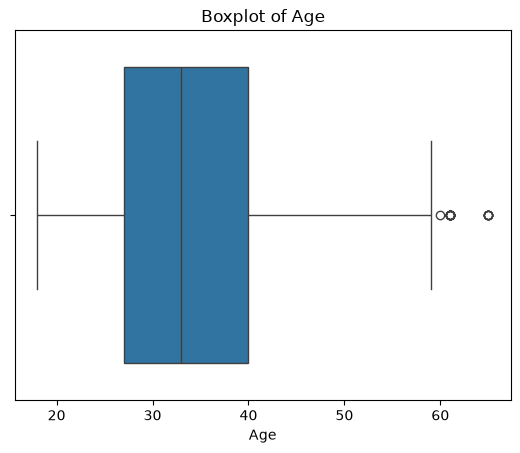

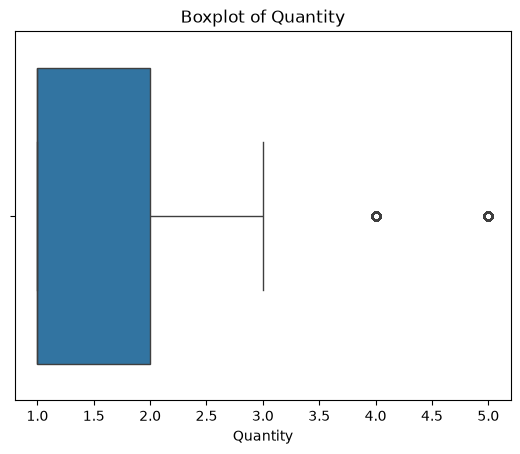

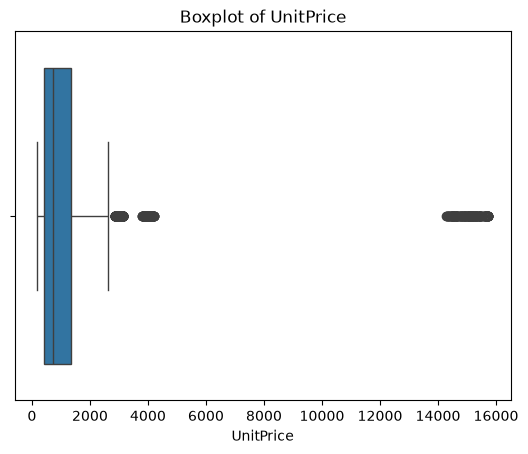

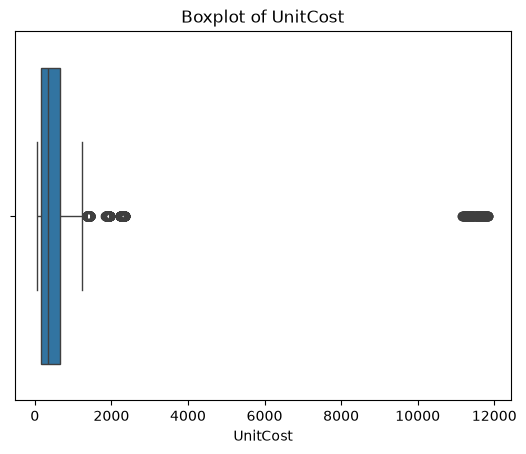

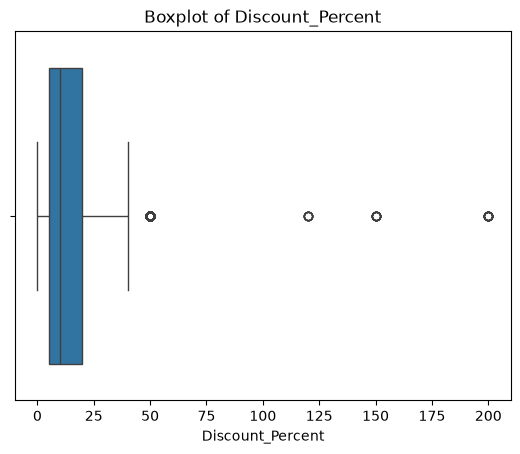

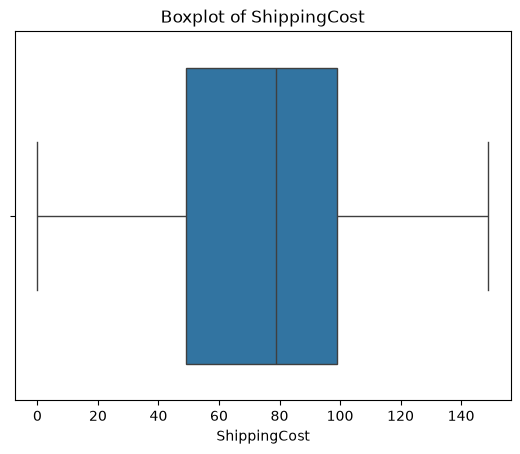

In [41]:
numerical_cols = ['Age','Quantity','UnitPrice','UnitCost','Discount_Percent','ShippingCost']

# visual representation
for col in numerical_cols:
    plt.Figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [42]:
for cols in numerical_cols:
    Q1 = df[cols].quantile(0.25)
    Q3 = df[cols].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers_count = df[(df[cols] < lower_bound) | (df[cols] > upper_bound)].shape[0]
    print(f"Outliers in {cols} : {outliers_count}")

Outliers in Age : 21
Outliers in Quantity : 912
Outliers in UnitPrice : 649
Outliers in UnitCost : 826
Outliers in Discount_Percent : 200
Outliers in ShippingCost : 0


`Age` - 60,61 and 65 are pointed out as outlier but these are valid age so keep those rows 

`Quantity` - Keep bcs Bulk purchases are common in e-commerce/B2B.

`Unitprice` - Keep bcs Expensive products are valid business values.

`UnitCost` - keep bcs High-cost products naturally exist.

`Discount_Percent` - will treat outliers as (120,150,200) % discount values are present which is not possible 

In [43]:
# 60,61 and 65 are pointed out as outlier but these are valid age so keep those rows
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df[(df["Age"] < lower) | (df["Age"] > upper)]

,OrderID,OrderLineID,InvoiceDate,CustomerID,Gender,Age,City,SignupDate,ProductID,ProductName,Category,Quantity,UnitPrice,UnitCost,Discount_Percent,ShippingCost,PaymentMethod,OrderStatus,ReturnReason
42,ORD109247,L17395,2024-02-12,21057,Female,61,hyderabad,2023-11-12,P1003,Bluetooth Speaker,Electronics,2,2445.78,1361.26,25,49,Upi,Delivered,Not Returned
134,ORD109246,L17392,2024-02-01,21057,Female,61,hyderabad,2023-11-12,P1001,Smartphone,Electronics,1,15734.82,11203.32,15,49,Net Banking,Delivered,Not Returned
1072,ORD111541,L21766,2024-10-15,21311,Female,61,mumbai,2023-02-11,P1006,USB-C Cable,Electronics,1,299.90,89.88,10,49,Upi,Delivered,Not Returned
1151,ORD109251,L17403,2024-05-22,21057,Female,61,hyderabad,2023-11-12,P1045,Pen Drive 64GB,Books And Stationery,1,831.34,388.75,20,0,Cash On Delivery,Delivered,Not Returned
1807,ORD109252,L17405,2024-06-24,21057,Female,61,hyderabad,2023-11-12,P1045,Pen Drive 64GB,Books And Stationery,1,793.06,403.41,0,79,Cash On Delivery,Delivered,Not Returned
2487,ORD109248,L17398,2024-02-04,21057,Female,61,hyderabad,2023-11-12,P1007,Webcam,Electronics,4,1753.35,965.86,5,0,Cash On Delivery,Delivered,Not Returned
2535,ORD105615,L10528,2023-10-13,20630,Female,65,mumbai,2023-04-17,P1036,Resistance Bands Set,Sports And Fitness,2,603.52,223.93,30,0,Debit Card,Delivered,Not Returned
2778,ORD105618,L10534,2024-02-02,20630,Female,65,mumbai,2023-04-17,P1047,Scientific Calculator,Books And Stationery,1,683.82,304.03,0,149,Net Banking,Delivered,Not Returned
3892,ORD109255,L17411,2024-08-20,21057,Female,61,hyderabad,2023-11-12,P1009,Women's Kurti,Fashion,1,859.88,341.29,40,0,Cash On Delivery,Delivered,Not Returned
5793,ORD105616,L10529,2023-10-18,20630,Female,65,mumbai,2023-04-17,P1050,Green Tea Box,Grocery And Gourmet,2,285.28,151.34,25,99,Net Banking,Delivered,Not Returned


In [44]:
df[df['Discount_Percent']>=100].shape # there are 29 rows which has discount values greater than 100 

(29, 19)

In [45]:
df=df[df['Discount_Percent'] <= 100] # kept only those rows where discount is maximum 100 % 

## Feature Engineering

### 1. Revenue

In [46]:
df['Revenue'] = df['UnitPrice'] * df['Quantity'] * (1 - df['Discount_Percent']/100)

### 2. Total Cost

In [47]:
df['Total_Cost'] = df['UnitCost'] * df['Quantity']

### 3.Profit

In [48]:
df['Profit'] = df['Revenue'] - df['Total_Cost'] - df['ShippingCost']

### 4. Profit Margin (%)

In [49]:
df["ProfitMargin"] = (df["Profit"] / df["Revenue"]) * 100

### 5. CustomerTenure

In [50]:
df['CustomerTenure'] = (df['InvoiceDate'] - df['SignupDate']).dt.days
df = df[df["CustomerTenure"] >= 0]

### 6. OrderMonth

In [51]:
df['OrderMonth'] = df['InvoiceDate'].dt.month_name()

### 7. Last Purchase Date

In [52]:
df["LastPurchaseDate"] = df.groupby("CustomerID")["InvoiceDate"].transform("max")

### 8. Recency

In [53]:
ReferenceDate = df['InvoiceDate'].max()   # reference date is last ordered date (latest) as per data se 
df['Recency'] = (ReferenceDate - df['LastPurchaseDate']).dt.days

### 9.Derive Churn
We'll use a `90-day rule` initially.

In [54]:
df['Churn'] = np.where(df['Recency']>90,'Yes','No')

### 10. Repeat Cuctomer

In [55]:
df['RepeatCustomer'] = np.where(df.groupby("CustomerID")["OrderID"].transform("count")>1,
                                  "Yes",
                                  "No"
                                  )

# 
Exploratory Data Analysis (EDA)
## Section 1: Univariate Analysis

### Business Question 1 -> What is the age distribution of our customers?

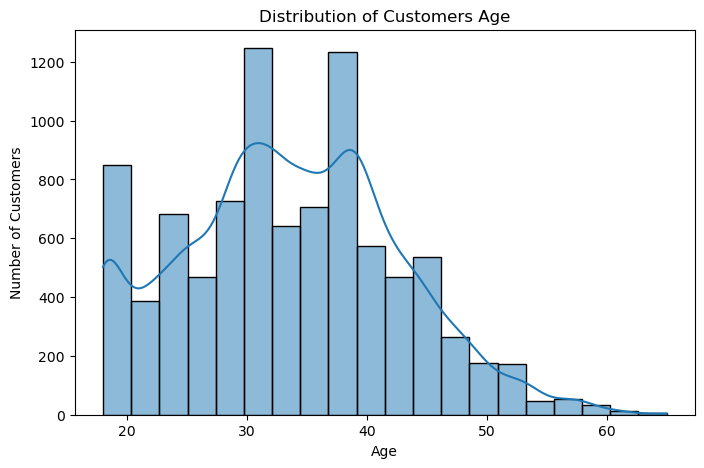

In [125]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'],bins=20,kde=True)
plt.title("Distribution of Customers Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

### Business Question 2 -> What is the gender distribution?

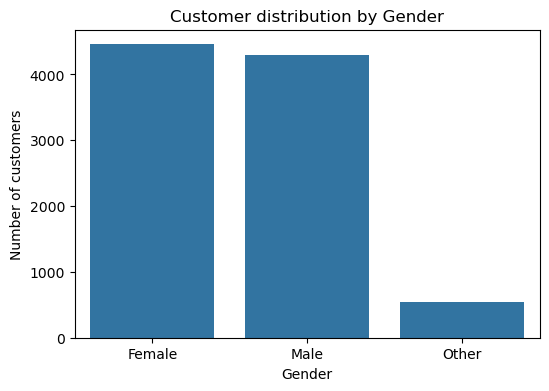

In [126]:
plt.figure(figsize=(6,4))
sns.countplot(x="Gender",data=df)
plt.title("Customer distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of customers")
plt.show()

### Business Question 3 -> Which cities have the most customers?

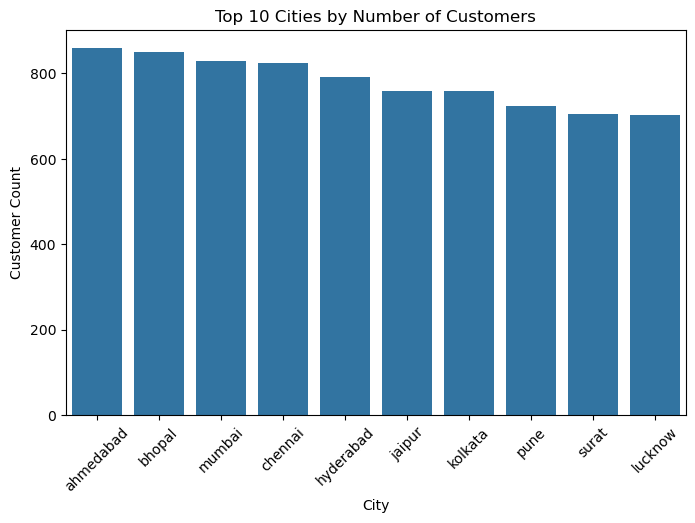

In [127]:
top_cities = df['City'].value_counts().head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=top_cities.index,y=top_cities.values)
plt.title("Top 10 Cities by Number of Customers")
plt.xlabel("City")
plt.ylabel("Customer Count")
plt.xticks(rotation=45)

plt.show()


### Business Question 4-> Which product categories receive the most orders?

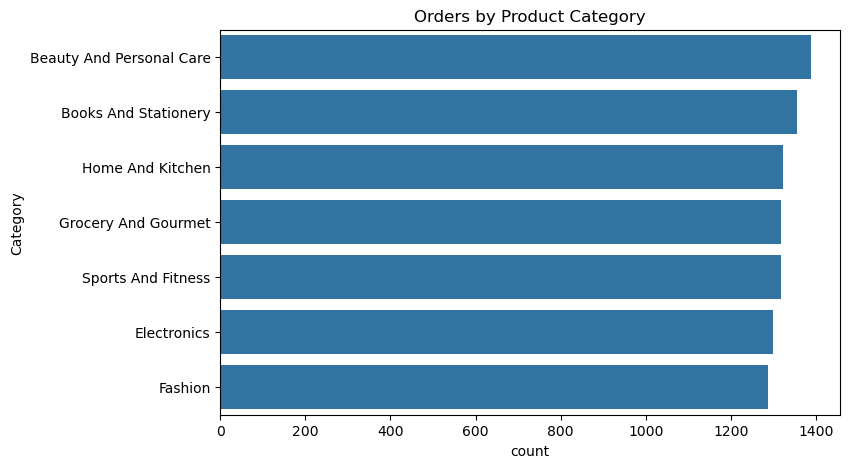

In [128]:
plt.figure(figsize=(8,5))
sns.countplot(y="Category",
              data=df,
              order=df["Category"].value_counts().index)

plt.title("Orders by Product Category")

plt.show()

### Business Question 5-> Which payment methods are most popular?

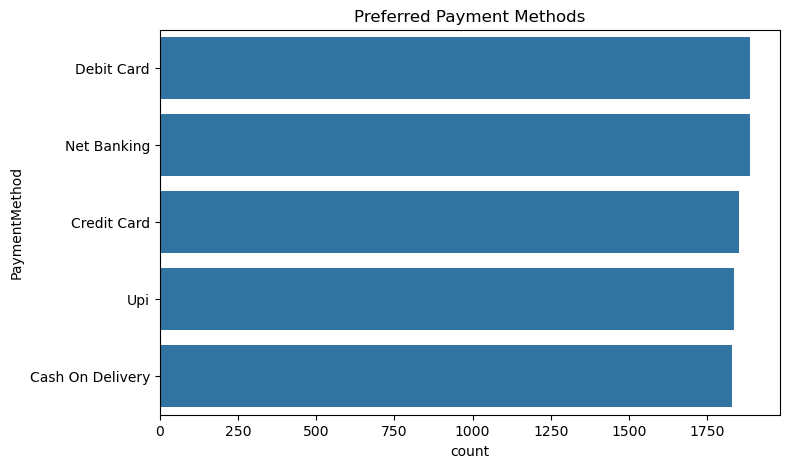

In [129]:
plt.figure(figsize=(8,5))
sns.countplot(y="PaymentMethod",
              data=df,
              order=df["PaymentMethod"].value_counts().index)

plt.title("Preferred Payment Methods")

plt.show()

## Section 2: Bivariate Analysis

### Business Question 6-> Which product categories generate the highest revenue?

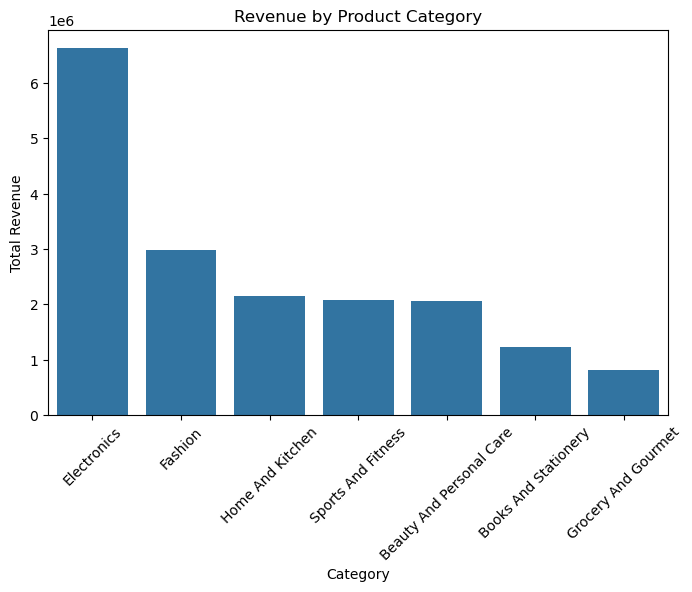

In [130]:
category_revenue = (
    df.groupby("Category")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
sns.barplot(x=category_revenue.index, y=category_revenue.values)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

### Business Question 7-> Which product categories generate the highest profit?

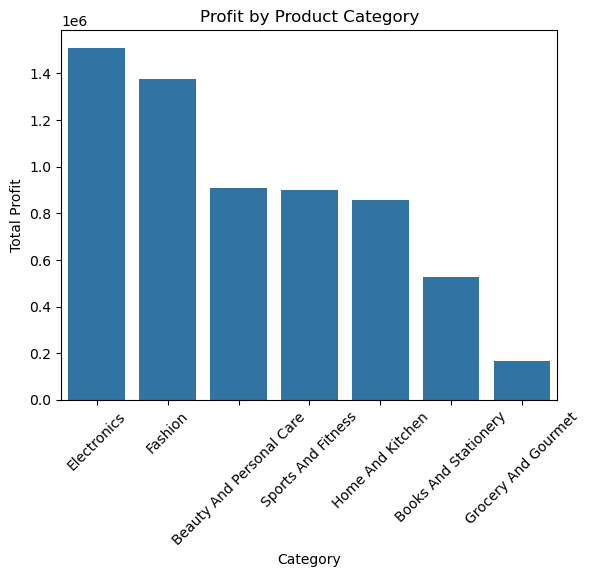

In [131]:
category_profit = (df.groupby("Category")["Profit"]
                    .sum()
                    .sort_values(ascending=False)
                    )
plt.Figure(figsize=(6,4))
sns.barplot(x=category_profit.index,y=category_profit.values)
plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

### Business Question 8 -> How does profit change over time?

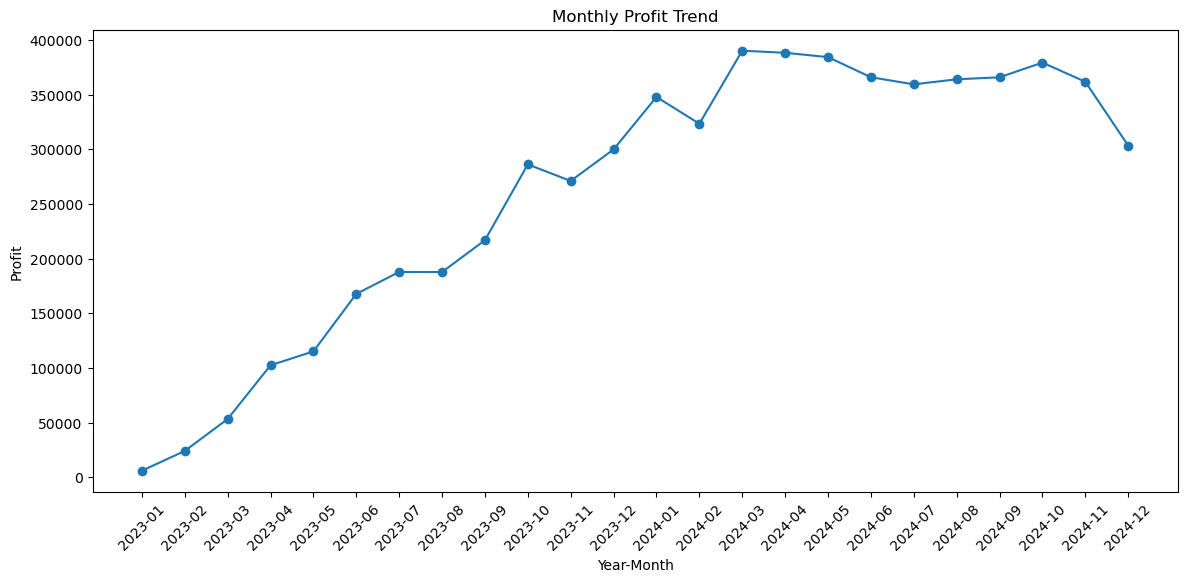

In [132]:
monthly_profit = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["Profit"]
      .sum()
)

plt.figure(figsize=(14,6))
plt.plot(monthly_profit.index.astype(str), monthly_profit.values, marker="o")

plt.title("Monthly Profit Trend")
plt.xlabel("Year-Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)

plt.show()

### Business Question 9 -> Who are the top 10 customers by revenue?

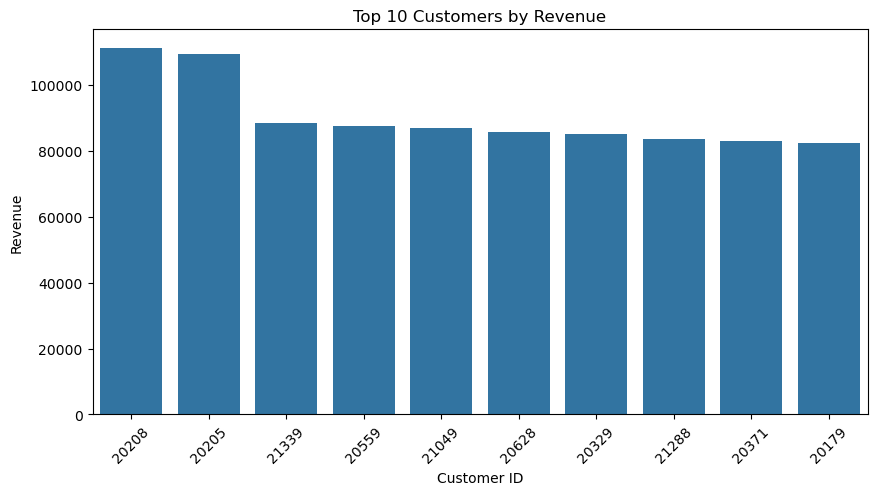

In [133]:
top_customers = (
    df.groupby("CustomerID")["Revenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(x=top_customers.index.astype(str), y=top_customers.values)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.show()

### Business Question 10 -> Does customer tenure affect churn?

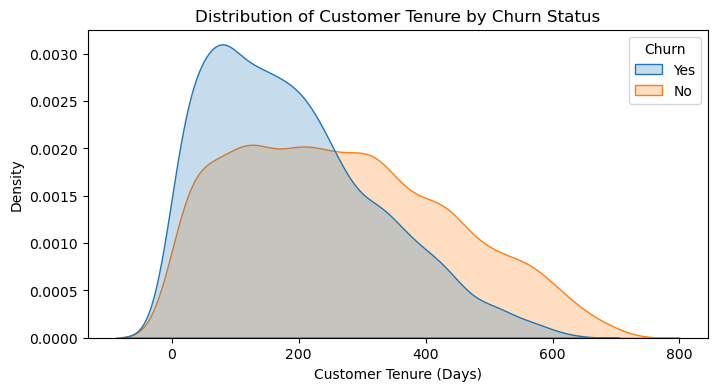

In [134]:
plt.figure(figsize=(8, 4))
sns.kdeplot(data=df, x="CustomerTenure", hue="Churn", common_norm=False, fill=True)

plt.title("Distribution of Customer Tenure by Churn Status")
plt.xlabel("Customer Tenure (Days)")
plt.show()

## Section 3 - Multivariate Analysis

### Business Question 11 -> Which categories generate the highest revenue across different payment methods?

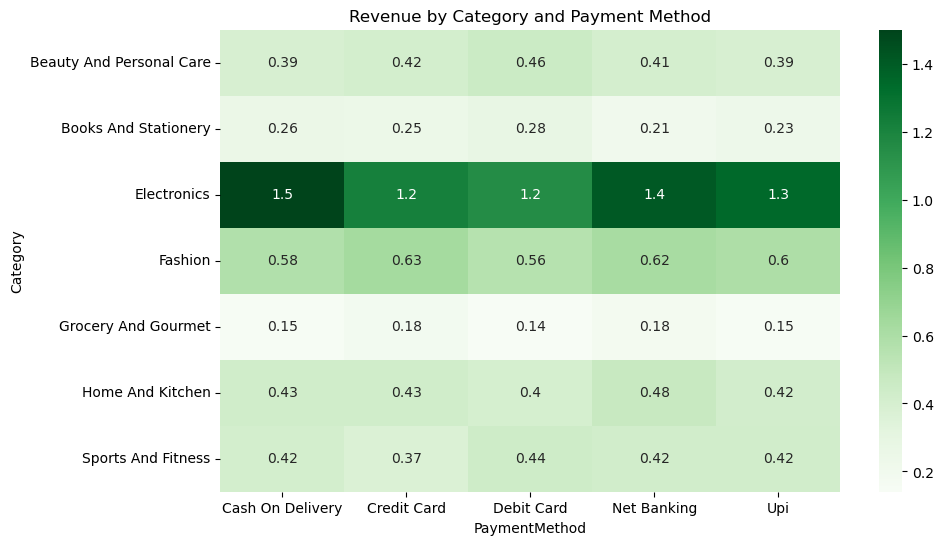

In [135]:
pivot = df.pivot_table(
    values="Revenue",
    index="Category",
    columns="PaymentMethod",
    aggfunc="sum"
)
pivot_in_millions = pivot / 1000000
plt.figure(figsize=(10,6))
sns.heatmap(pivot_in_millions, annot=True,cmap="Greens")

plt.title("Revenue by Category and Payment Method")
plt.show()

### Business Question 12 -> Which cities and categories generate the highest profit?

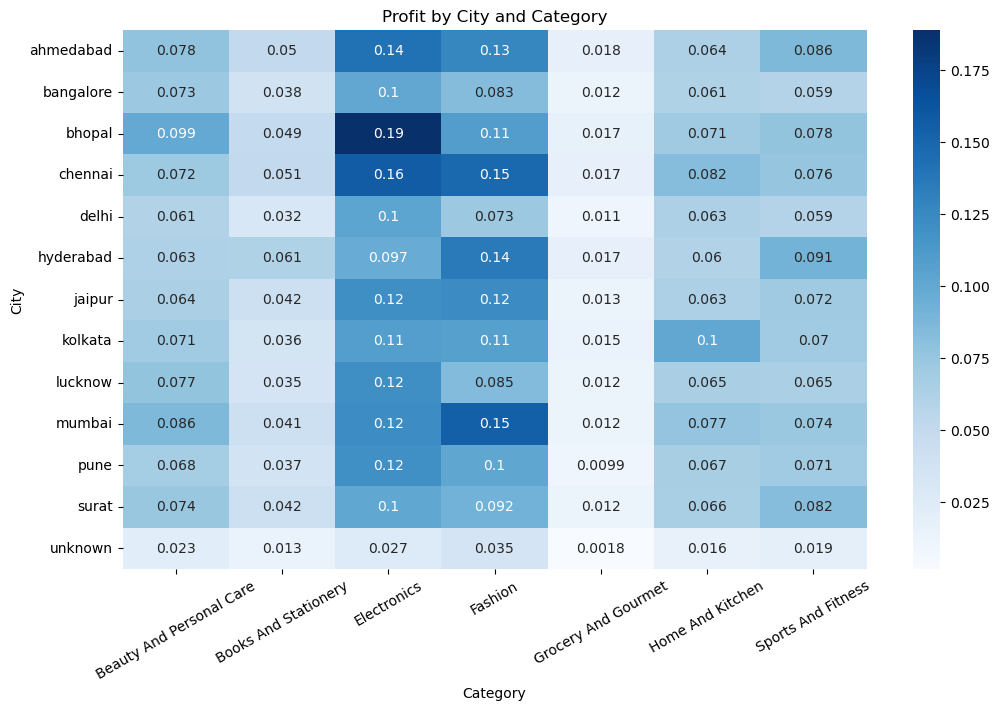

In [136]:
pivot = df.pivot_table(
    values="Profit",
    index="City",
    columns="Category",
    aggfunc="sum"
)
pivot_in_millions = pivot / 1000000
plt.figure(figsize=(12,7))
sns.heatmap(pivot_in_millions, annot=True,cmap="Blues")
plt.xticks(rotation=30)

plt.title("Profit by City and Category")
plt.show()

### Business Question 14 (Churn) -> Which cities have the highest churn across different payment methods?

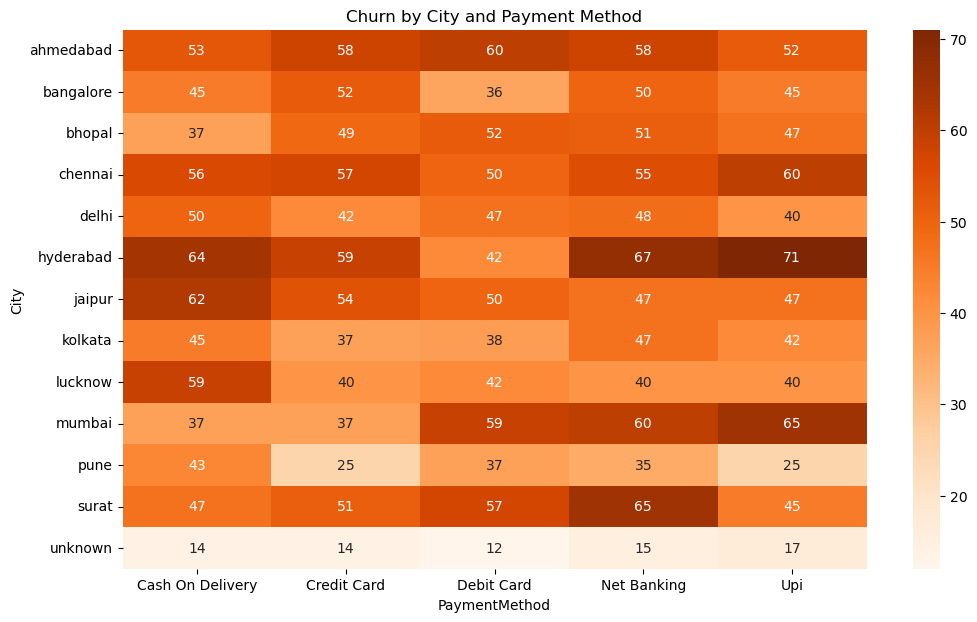

In [137]:
pivot = df.pivot_table(
    values="CustomerID",
    index="City",
    columns="PaymentMethod",
    aggfunc=lambda x: (df.loc[x.index, "Churn"] == "Yes").sum()
)

plt.figure(figsize=(12,7))
sns.heatmap(pivot,annot=True, cmap="Oranges")

plt.title("Churn by City and Payment Method")
plt.show()

# Statistical Analysis

The purpose of statistical analysis is to prove whether the patterns we saw in EDA are statistically meaningful or could have occurred by chance.

## Question - Which numerical variables are strongly related to each other?

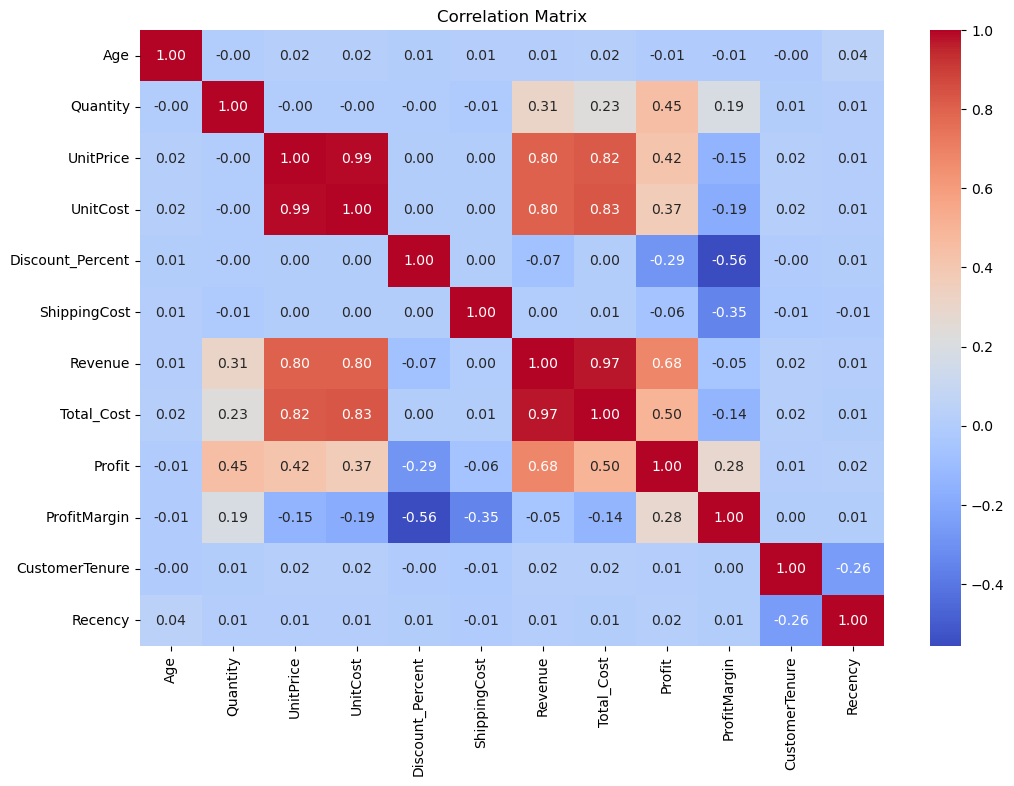

In [138]:
numerical_cols = [
    "Age",
    "Quantity",
    "UnitPrice",
    "UnitCost",
    "Discount_Percent",
    "ShippingCost",
    "Revenue",
    "Total_Cost",
    "Profit",
    "ProfitMargin",
    "CustomerTenure",
    "Recency"
]

corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

## Business Question -> Does giving higher discounts significantly reduce profit?
### Correlation Test (Discount vs Profit)

In [139]:
from scipy.stats import pearsonr

corr, p_value = pearsonr(
    df["Discount_Percent"],
    df["Profit"]
)

print("Correlation:", corr)
print("P-value:", p_value)

Correlation: -0.28642663504577554
P-value: 6.508543637708916e-175


`Correlation` = -0.286
The relationship is `negative`.

Interpretation: As the `Discount_Percent increases, Profit tends to decrease`.

`P-value` = 6.51 × 10^(-175)  This value is far smaller than 0.05.

6.51 × 10^(-175) < 0.05 : Reject the Null Hypothesis

This means: `Higher discounts are associated with lower profits`

# Business Insights

### 1. Electronics is the company's strongest category.
Electronics generated the highest revenue as well as the highest total profit, making it the primary revenue and profitability driver.

### 2. Fashion is the second-best performing category.
Fashion consistently ranks second in both revenue and profit, making it another strategically important category for business growth.

### 3. Grocery & Gourmet is underperforming.
Despite having a customer base, Grocery & Gourmet contributes the lowest revenue and the lowest profit, indicating poor financial performance compared to other categories.

### 4. Customer purchases are well distributed across payment methods.
The five payment methods have very similar usage counts (around 1,850–1,925 transactions each), suggesting customers are comfortable using multiple payment options

### 5.Customer base is balanced across genders.

The dataset contains approximately:

Female: 4,526
Male: 4,359
Other: 550 (This indicates a relatively balanced customer distribution with no heavy dependence on a single gender segment.)

### 6. Ahmedabad has the largest customer base.

Ahmedabad records the highest number of customers, followed closely by Bhopal and Mumbai.

### 7. Longer customer tenure is associated with lower churn.

Your Customer Tenure vs Churn visualization shows that customers with longer tenure are more likely to remain active, whereas churned customers are concentrated in lower tenure ranges. This highlights the importance of retaining customers during their early lifecycle.

### 8. Higher discounts are associated with lower profitability.

Pearson correlation analysis showed a statistically significant negative relationship between `Discount Percentage` and `Profit` (`r = -0.286`, `p < 0.001`). This indicates that higher discounts generally reduce profitability, highlighting the need for a balanced discount strategy.

### 9. Bonus Insight (from your data cleaning)

During feature engineering, 116 records produced negative customer tenure because the invoice date occurred before the signup date. These logically impossible records were identified as data quality issues and removed before analysis to ensure reliable business insights.

# Business Recommendations

### 1. Optimize discount strategies

Since higher discounts are associated with lower profitability, the company should avoid excessive discounting and offer targeted promotions to maintain both sales and profit margins.

### 2. Increase investment in high-performing categories

Since Electronics and Fashion generate the highest revenue and profit, the company should prioritize these categories by increasing inventory, launching promotional campaigns, and expanding product offerings to maximize revenue growth.

### 3. Improve Grocery & Gourmet through better pricing, promotions, and product strategy.

### 4. Launch loyalty programs to retain long-term customers and reduce churn.

### 5. Strengthen marketing in top-performing cities like Ahmedabad, Bhopal, and Mumbai.

### 6. Strengthen data quality monitoring

Several data quality issues were identified, including negative customer tenure, unrealistic ages, invalid discounts, duplicate records, and inconsistent category names.

## Executive Summary

This project analyzed an e-commerce dataset to understand `customer behavior`, `profitability`, and `customer churn`. The data was cleaned, transformed, and enriched by engineering features such as `Revenue`, `Profit`, `Profit Margin`, `Customer Tenure`, `Recency`, `Churn`, and `Repeat Customer`.

EDA revealed that `Electronics` and `Fashion` were the top-performing categories, while `Grocery & Gourmet` generated the lowest revenue and profit. Customers with `longer tenure` were less likely to churn, and a small group of customers contributed a significant share of total revenue.

Statistical analysis found a `significant negative relationship` between `Discount Percentage` and `Profit` (`r = -0.286`, `p < 0.001`), indicating that higher discounts generally reduce profitability.

Based on these findings, the company should focus on `high-performing categories`, `customer retention`, `optimized discount strategies`, `high-value customers`, and `data quality` to improve overall business performance.